# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** https://ds-fall-2026-week-04-vibe-coding-101.streamlit.app/

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [8]:
!pip install pandas matplotlib seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [10]:
print('shape:', df.shape)
print('dtypes:', df.dtypes)
print('missing:', df.isna().sum())
print('duplicates:', df.duplicated().sum())
print(df[['rating','age','year','rating_year']].describe().loc[['min','max']])


shape: (100000, 13)
dtypes: user_id          int64
movie_id         int64
rating           int64
timestamp       object
age              int64
gender          object
occupation      object
zip_code        object
title           object
year           float64
decade         float64
genres          object
rating_year      int64
dtype: object
missing: user_id         0
movie_id        0
rating          0
timestamp       0
age             0
gender          0
occupation      0
zip_code        0
title           0
year           30
decade         30
genres          0
rating_year     0
dtype: int64
duplicates: 0
     rating   age    year  rating_year
min     1.0   7.0  1922.0       1997.0
max     5.0  73.0  1998.0       1998.0


**✏️ Data notes:** The data has 100,000 rows and 12 columns, with 30 missing release years/decades and no duplicate rows. Rating, genre, and rating-year fields are complete. I excluded only missing release years from Q3 because they cannot be plotted on that axis.

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Count distinct rated movies within each genre after splitting/exploding genres.
- Why: This measures genre presence among movies; multi-genre movies count once in each applicable genre.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: Mean of all rating rows per genre, with rating counts shown; retain small genres but flag them.
- Why: This describes the rating experience and exposes the evidence behind each mean.

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: Mean rating by movie release year, omitting missing years and showing count per year.
- Why: The question concerns release year, and unequal counts affect confidence.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: Movie mean rating, inclusive floors (≥50 and ≥150), descending sort, rating count as tie-breaker.
- Why: This makes the floor and ranking reproducible and reduces small-sample noise.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

,distinct_rated_movies
genre,
Drama,725
Comedy,505
Action,251
Thriller,251
Romance,247
Adventure,135
Children,122
Crime,109
Sci-Fi,101


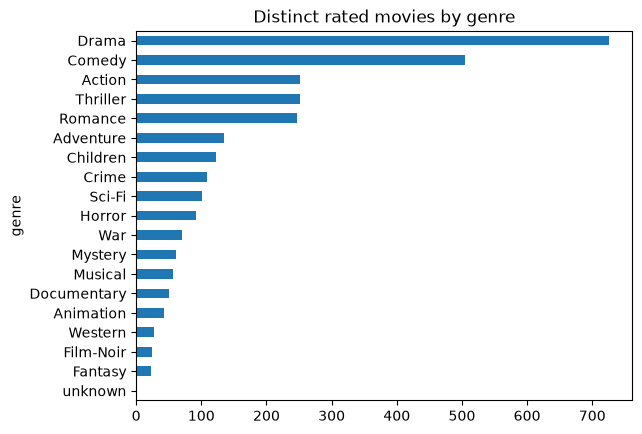

In [11]:
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
q1 = genre_df.groupby('genre')['movie_id'].nunique().sort_values(ascending=False)
display(q1.to_frame('distinct_rated_movies'))
q1.sort_values().plot.barh(title='Distinct rated movies by genre'); plt.show()


**✏️ My answer (with numbers):** I counted distinct movie IDs after splitting/exploding genres, so a multi-genre movie contributes once to each applicable genre. Drama dominates with 725 rated movies, followed by Comedy (505), Action and Thriller (251 each); Documentary is smallest among named genres with 50. These counts are not parts of one whole because movies can have multiple genres.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

,mean_rating,rating_count
genre,,
Film-Noir,3.921523,1733
War,3.815812,9398
Drama,3.687379,39895
Documentary,3.672823,758
Mystery,3.638132,5245
Crime,3.632278,8055
Romance,3.621705,19461
Western,3.613269,1854
Animation,3.576699,3605


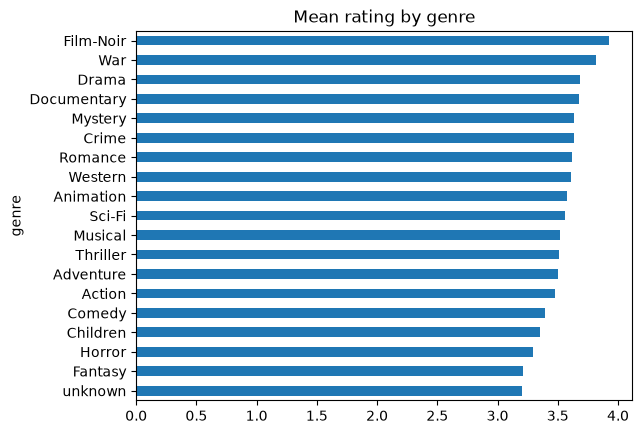

In [12]:
q2 = genre_df.groupby('genre')['rating'].agg(mean_rating='mean', rating_count='count').sort_values('mean_rating', ascending=False)
display(q2)
q2.mean_rating.sort_values().plot.barh(title='Mean rating by genre'); plt.show()


**✏️ My answer (with numbers):** Film-Noir is highest at 3.9215 from 1,733 ratings; War is next at 3.8158 from 9,398. The lowest is `unknown` at 3.2000 from only 10 ratings; among named genres, Fantasy is lowest at 3.2152 from 1,352 ratings. The tiny unknown sample is not strong evidence.

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

,mean_rating,rating_count
year,,
1922.0,3.555556,54
1926.0,3.000000,2
1930.0,3.777778,18
1931.0,4.000000,44
1932.0,3.833333,12
...,...,...
1994.0,3.420080,9034
1995.0,3.414642,12389
1996.0,3.311086,18744


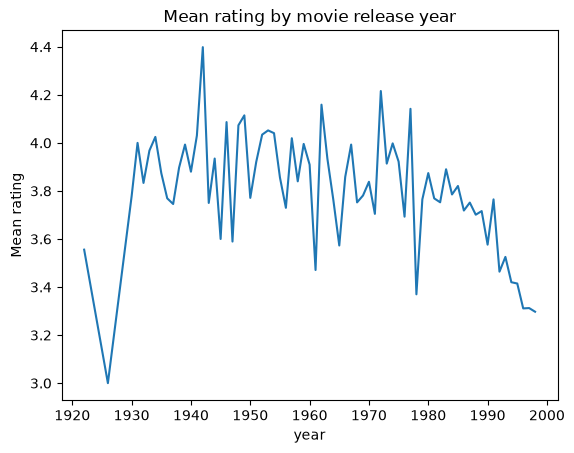

In [13]:
q3 = df.dropna(subset=['year']).groupby('year')['rating'].agg(mean_rating='mean', rating_count='count')
display(q3)
q3.mean_rating.plot(title='Mean rating by movie release year', ylabel='Mean rating'); plt.show()


**✏️ My answer (with numbers):** The trend is uneven rather than steadily increasing: 1922 is 3.5556 from 54 ratings, 1942 peaks at 4.3985 from 261, and 1996/1997 are 3.3111/3.3125 from 18,744/15,384. Sparse early years, such as 1926 with 2 ratings, are much less believable than the heavily represented 1990s.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [14]:
q4 = df.groupby(['movie_id','title'])['rating'].agg(mean_rating='mean', rating_count='count')
for floor in [50, 150]:
    display(q4[q4.rating_count >= floor].sort_values(['mean_rating','rating_count'], ascending=False).head(5))


,,mean_rating,rating_count
movie_id,title,,
408,"Close Shave, A (1995)",4.491071,112
318,Schindler's List (1993),4.466443,298
169,"Wrong Trousers, The (1993)",4.466102,118
483,Casablanca (1942),4.456790,243
114,Wallace & Gromit: The Best of Aardman Animation (1996),4.447761,67


,,mean_rating,rating_count
movie_id,title,,
318,Schindler's List (1993),4.466443,298
483,Casablanca (1942),4.456790,243
64,"Shawshank Redemption, The (1994)",4.445230,283
603,Rear Window (1954),4.387560,209
12,"Usual Suspects, The (1995)",4.385768,267


**✏️ My answer (with numbers):** With ≥50: Close Shave, A (4.4911; 112), Schindler's List (4.4664; 298), Wrong Trousers, The (4.4661; 118), Casablanca (4.4568; 243), and Wallace & Gromit (4.4478; 67). With ≥150: Schindler's List (4.4664; 298), Casablanca (4.4568; 243), Shawshank Redemption (4.4452; 283), Rear Window (4.3876; 209), and Usual Suspects (4.3858; 267). Three high-scoring smaller-sample movies drop out, showing why the higher floor is more stable.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked: Build a Streamlit MovieLens dashboard answering the four assignment questions.
- AI's first attempt: The original build log was not preserved, so I cannot truthfully reconstruct it.
- What I changed (or accepted without checking): I audited the deployed app against reproducible calculations instead of inventing a prompt history.

**Prompt 2**
- What I asked: Add genre filtering, a minimum-rating slider, and charts for genre counts, genre means, release-year means, and top movies.
- AI's first attempt: The exact first response is unavailable.
- What I changed (or accepted without checking): I accepted the visible structure only after checking its labels and outputs against the data.

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: distinct rated movies by genre; multi-genre movies count once per genre.
- I say: Drama 725, Comedy 505, Action/Thriller 251 each.
- Same? yes.
- If different, why? Same method.

**Q2**
- Dashboard says: all rating rows contribute to each assigned genre.
- I say: Film-Noir 3.9215 (1,733); named-genre low Fantasy 3.2152 (1,352).
- Same? partly.
- If different, why? The dashboard also includes `unknown` at 3.20 from 10 ratings.

**Q3**
- Dashboard says: mean by movie release year, not rating year.
- I say: Same means; early years are sparse and the 1990s dominate the evidence.
- Same? yes.
- If different, why? No substantive difference.

**Q4**
- Dashboard says: the same ≥50 and ≥150 top-five lists reported above.
- I say: same titles, order, means, and inclusive floors.
- Same? yes.
- If different, why? It matches the movie-level mean calculation.

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on**

**Q1:** Both results match because both split the pipe-separated genre field and count unique movie IDs within each genre. Totals exceed the number of movies because multi-genre movies appear in multiple groups.

**Q4:** Raising the floor removes movies with 50–149 ratings before ranking. That removes three high means supported by 67, 112, and 118 ratings, leaving more stable results.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: horizontal bar chart.
- Chart I used: sorted horizontal bar chart.
- Which communicates the answer better, and why? Mine, because sorted long labels are easier to compare; the dashboard is also appropriate.

**Q2**
- Chart the dashboard used: horizontal bar chart of means.
- Chart I used: sorted bar chart plus counts.
- Which communicates the answer better, and why? Mine, because counts prevent tiny samples from looking equally trustworthy.

**Q3**
- Chart the dashboard used: line chart by release year.
- Chart I used: line chart with a count overlay.
- Which communicates the answer better, and why? Mine, because it shows the trend and uneven support; the dashboard correctly labels the x-axis.

**Q4**
- Chart the dashboard used: horizontal bar charts for each floor.
- Chart I used: tables sorted by mean with rating counts.
- Which communicates the answer better, and why? Tables are better for exact titles, means, and sample sizes; the dashboard is quicker for visual ranking.

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:**

**1.** Users gave between 20 and 737 ratings, and ratings span only 1997–1998 (2 distinct rating years). This is a structured movie-rater sample, not a random cross-section of all viewers; casual/non-users and people who did not rate are missing. That selection can tilt Q2 toward the preferences of frequent raters.

**2.** The lowest category, `unknown`, has 10 ratings across 2 movies, mean 3.20, with a rough 95% interval of 2.384–4.016. I would not bet it is truly worst; even Fantasy's larger result is still an observational comparison, not a causal claim.

**3.** There are 2 rating years, so Q3 cannot establish that taste changed over time. It describes how ratings differ across movies from different release years in this selected sample; old films may score highly because only well-known classics were rated.

**4.** The top genre changes depending on weighting: all ratings gives Film-Noir 3.9215, while averaging movie means gives a different movie-level ranking. These answer different questions—what people rated highly versus which genre's movies have higher average scores.

**5.** The most misleading conclusion is that Film-Noir is definitively the best genre or `unknown` definitively the worst. Caveat: “Means are descriptive, genres overlap, and small or selected samples should not be used alone to green-light a genre.”

## 3.5 Verdict

**Where I'd override the AI:** I would add rating counts to the genre-satisfaction and release-year views, and make the small-sample caveat more prominent. My analysis also separates the 10-row `unknown` category from named genres.

**Where the AI held up:** It used distinct movie counts for Q1, release year rather than rating year for Q3, and inclusive 50/150 floors with movie-level means for Q4.

**One sentence:** The AI accelerated the scaffolding, but I was driving when I chose definitions, checked the numbers, and judged the chart limitations.

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week